# Assignment 08: Grouped Summaries of an Imaging Network

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import pyarrow

print("pandas:", pd.__version__)
print("pyarrow:", pyarrow.__version__)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

MISSING_PATH = OUTPUT_DIR / "missing_by_modality.csv"
SITE_SUMMARY_PATH = OUTPUT_DIR / "site_summary.csv"
SITE_MODALITY_PATH = OUTPUT_DIR / "site_modality_summary.csv"
DELAYED_STAT_PATH = OUTPUT_DIR / "delayed_stat_exams.csv"
CT_DOSE_PATH = OUTPUT_DIR / "ct_dose_review.csv"
SLOWEST_PATH = OUTPUT_DIR / "slowest_stat_reports.csv"
PIVOT_PATH = OUTPUT_DIR / "median_report_pivot.csv"
PAIRPLOT_PNG = OUTPUT_DIR / "pairplot.png"  # seaborn route
PAIRPLOT_HTML = OUTPUT_DIR / "pairplot.html"  # Altair route: one of these two
PAIRPLOT_JSON = OUTPUT_DIR / "pairplot.json"

pandas: 3.0.5
pyarrow: 25.0.0


## Load the data

This cell downloads the exam log from the course repository when `data/` lacks it (`urlretrieve(url, path)` saves the file at a web address to `path`), then reads it: one row per exam. Run it as it is.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/christopherseaman/datasci_217/main/08/assignment/data"
DATA_FILES = ["imaging_exams.parquet"]

DATA_DIR.mkdir(exist_ok=True)
for name in DATA_FILES:
    if not (DATA_DIR / name).exists():
        print("downloading", name)
        urlretrieve(f"{DATA_URL}/{name}", DATA_DIR / name)

exams = pd.read_parquet(DATA_DIR / "imaging_exams.parquet")
print("exams:", exams.shape)
exams.head()

exams: (540228, 15)


,exam_id,patient_id,site,exam_date,age,sex,setting,priority,modality,body_region,scan_min,dose_msv,wait_hr,report_hr,reader_id
0,E0000001,P077750,Northgate,2025-01-01,67,M,Inpatient,Routine,Ultrasound,Abdomen/Pelvis,28,NaN,43.3,11.12,T04
1,E0000002,P164273,Downtown,2025-01-01,75,M,Inpatient,Urgent,MRI,Extremity,51,NaN,9.0,1.75,T01
2,E0000003,P198046,Northgate,2025-01-01,70,M,Inpatient,STAT,CT,Head,12,2.188,2.6,2.11,T02
3,E0000004,P134356,Northgate,2025-01-01,50,F,ED,STAT,X-ray,Chest,7,0.023,0.5,NaN,T02
4,E0000005,P054587,Harbor,2025-01-01,7,M,ED,Urgent,X-ray,Spine,7,0.404,12.1,4.16,T02


## Task 1: Explore the log and summarize each site

### 1.1 Explore the exam log

> **Checkpoint: `output/pairplot.png`, or `output/pairplot.html` or `.json`**
> One pairplot of all five numeric columns, from seaborn or Altair.

> **Checkpoint: `output/missing_by_modality.csv`**
> Four rows, `CT` to `X-ray`, under the header `modality,report_hr,dose_msv`.

In [3]:
distinct_exams = exams["exam_id"].nunique()
patients = exams["patient_id"].nunique()
print("rows:", len(exams))
print("distinct exams:", distinct_exams)
print("patients:", patients)

exams.info()
display(exams.describe(include="all"))

rows: 540228
distinct exams: 540228
patients: 210000
<class 'pandas.DataFrame'>
RangeIndex: 540228 entries, 0 to 540227
Data columns (total 15 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   exam_id      540228 non-null  str           
 1   patient_id   540228 non-null  str           
 2   site         540228 non-null  str           
 3   exam_date    540228 non-null  datetime64[ms]
 4   age          540228 non-null  int64         
 5   sex          540228 non-null  str           
 6   setting      540228 non-null  str           
 7   priority     540228 non-null  str           
 8   modality     540228 non-null  str           
 9   body_region  540228 non-null  str           
 10  scan_min     540228 non-null  int64         
 11  dose_msv     347619 non-null  float64       
 12  wait_hr      540228 non-null  float64       
 13  report_hr    537966 non-null  float64       
 14  reader_id    540228 non-null  str         

,exam_id,patient_id,site,exam_date,age,sex,setting,priority,modality,body_region,scan_min,dose_msv,wait_hr,report_hr,reader_id
count,540228,540228,540228,540228,540228.000000,540228,540228,540228,540228,540228,540228.000000,347619.000000,540228.000000,537966.000000,540228
unique,540228,210000,8,NaN,NaN,2,3,3,4,7,NaN,NaN,NaN,NaN,36
top,E0000001,P177810,Downtown,NaN,NaN,F,Outpatient,Routine,X-ray,Chest,NaN,NaN,NaN,NaN,R18
freq,1,82,129876,NaN,NaN,292569,327548,300434,219633,132027,NaN,NaN,NaN,NaN,18207
mean,NaN,NaN,NaN,2025-07-01 00:51:55.804000,56.140002,NaN,NaN,NaN,NaN,NaN,17.933854,2.522546,82.990732,9.562691,NaN
min,NaN,NaN,NaN,2025-01-01 00:00:00,1.000000,NaN,NaN,NaN,NaN,NaN,2.000000,0.000000,0.100000,0.050000,NaN
25%,NaN,NaN,NaN,2025-03-29 00:00:00,45.000000,NaN,NaN,NaN,NaN,NaN,8.000000,0.013000,1.500000,0.990000,NaN
50%,NaN,NaN,NaN,2025-06-30 00:00:00,58.000000,NaN,NaN,NaN,NaN,NaN,12.000000,0.031000,19.600000,5.640000,NaN
75%,NaN,NaN,NaN,2025-10-03 00:00:00,71.000000,NaN,NaN,NaN,NaN,NaN,24.000000,2.584000,96.100000,13.100000,NaN
max,NaN,NaN,NaN,2025-12-31 00:00:00,97.000000,NaN,NaN,NaN,NaN,NaN,153.000000,46.512000,4058.200000,252.500000,NaN


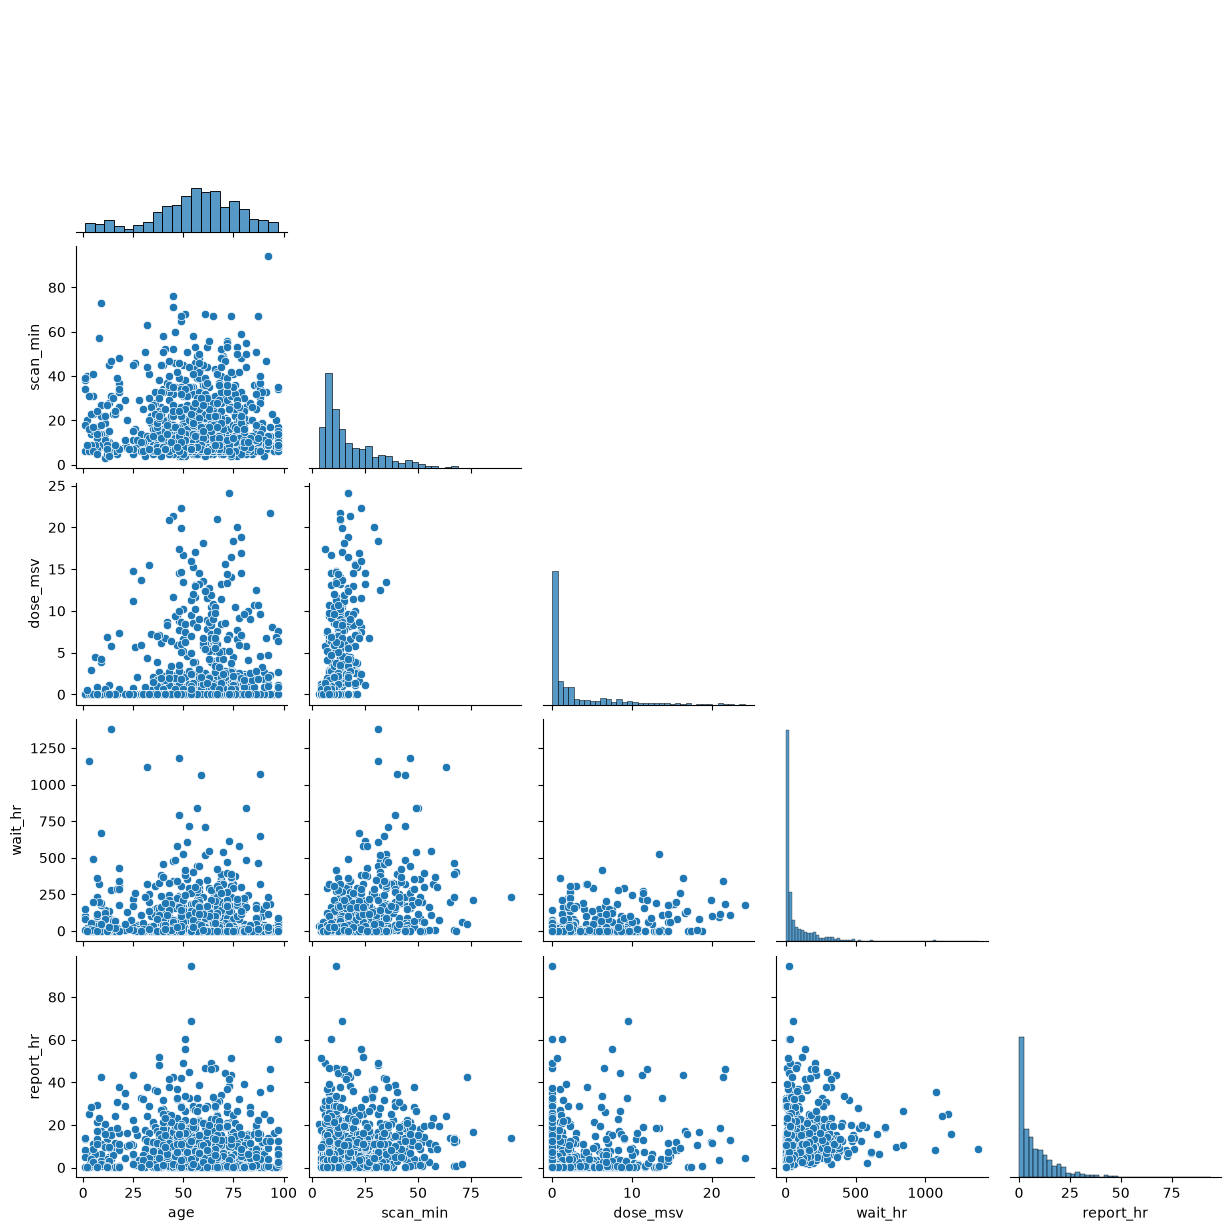

In [4]:
pairplot_columns = ["age", "scan_min", "dose_msv", "wait_hr", "report_hr"]
pairplot_sample = exams[pairplot_columns].sample(n=1000, random_state=27)

import seaborn as sns
import matplotlib.pyplot as plt
import altair as alt

sns.pairplot(pairplot_sample, corner=True)
plt.savefig(PAIRPLOT_PNG, bbox_inches="tight")

In [5]:
missing_by_modality = exams.groupby("modality")[["report_hr", "dose_msv"]].apply(lambda g: g.isna().mean())

missing_by_modality.to_csv(MISSING_PATH)

q1, q3 = exams["wait_hr"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
above_fence = (exams["wait_hr"] > upper).sum()
print("quartiles:", q1, q3)
print("upper fence:", upper)
print("waits above the fence:", above_fence)

quartiles: 1.5 96.1
upper fence: 237.99999999999997
waits above the fence: 55401


### 1.2 Put the sites in reporting order

This step saves nothing.

In [6]:
SITE_ORDER = ["Downtown", "Harbor", "Northgate", "Lakeside", "Hillcrest", "Riverside", "Westfield", "Valley", "Eastport"]  # Eastport opens in 2026

exams["site"] = pd.Categorical(exams["site"], categories=SITE_ORDER, ordered=True)
print("site dtype:", exams["site"].dtype)

exams_per_site = exams.groupby("site", observed=False, dropna=False).count()["exam_id"]
exams_per_site

site dtype: category


site
Downtown     129876
Harbor       108818
Northgate    120961
Lakeside      44420
Hillcrest     37883
Riverside     35660
Westfield     37226
Valley        25384
Eastport          0
Name: exam_id, dtype: int64

### 1.3 Count exams, reports, and patients, and total the scanner time

> **Checkpoint: `output/site_summary.csv`**
> Eight rows under the header `site,exam_count,report_count,patient_count,total_scan_min,mean_scan_min`.

In [7]:
site_summary = exams.groupby("site", as_index=False).agg(
    exam_count=("exam_id", "count"),
    report_count=("report_hr", "count"),
    patient_count=("patient_id", "nunique"),
    total_scan_min=("scan_min", "sum"),
    mean_scan_min=("scan_min", "mean")
)
print("rows:", len(site_summary))

site_summary.to_csv(SITE_SUMMARY_PATH, index=False)

site_summary

rows: 8


,site,exam_count,report_count,patient_count,total_scan_min,mean_scan_min
0,Downtown,129876,129366,60995,2239524,17.243555
1,Harbor,108818,108422,52764,1839569,16.905007
2,Northgate,120961,120484,61314,1999568,16.530683
3,Lakeside,44420,44206,26507,906052,20.397389
4,Hillcrest,37883,37689,22516,767578,20.261806
5,Riverside,35660,35487,21898,732561,20.542933
6,Westfield,37226,37032,23363,844368,22.682211
7,Valley,25384,25280,12905,359150,14.148676


## Task 2: Compare sites, modalities, and single exams

### 2.1 Summarize each site and modality

> **Checkpoint: `output/site_modality_summary.csv`**
> 31 rows under the header `site,modality,exam_count,median_wait_hr,median_report_hr`.

In [8]:
site_modality = exams.groupby(["site", "modality"], as_index=False).agg(
    exam_count=("exam_id", "count"),
    median_wait_hr=("wait_hr", "median"),
    median_report_hr=("report_hr", "median")
)
print("rows:", len(site_modality))

site_modality.to_csv(SITE_MODALITY_PATH, index=False)

site_modality

rows: 31


,site,modality,exam_count,median_wait_hr,median_report_hr
0,Downtown,CT,33864,2.40,1.610
1,Downtown,MRI,15687,269.00,13.190
2,Downtown,Ultrasound,26678,56.70,5.940
3,Downtown,X-ray,53647,5.50,3.080
4,Harbor,CT,29776,2.20,1.140
5,Harbor,MRI,12326,278.30,9.820
6,Harbor,Ultrasound,21573,51.20,4.250
7,Harbor,X-ray,45143,4.50,2.020
8,Northgate,CT,34188,1.60,1.110
9,Northgate,MRI,12900,227.50,10.865


### 2.2 Flag STAT exams that waited far longer than their peers

> **Checkpoint: `output/delayed_stat_exams.csv`**
> 190 rows under the header `exam_id,site,modality,wait_hr,peer_median_wait_hr,wait_vs_peer_hr`.

In [9]:
stat = exams[exams["priority"] == "STAT"].copy()
stat["peer_median_wait_hr"] = stat.groupby(["site", "modality"])["wait_hr"].transform("median")
stat["wait_vs_peer_hr"] = stat["wait_hr"] - stat["peer_median_wait_hr"]
print("STAT exams:", len(stat))

delayed_stat = stat[stat["wait_hr"] > 8][["exam_id", "site", "modality", "wait_hr", "peer_median_wait_hr", "wait_vs_peer_hr"]]
print("delayed:", len(delayed_stat))

delayed_stat.to_csv(DELAYED_STAT_PATH, index=False)

delayed_stat.sort_values("wait_hr", ascending=False).head(10)

STAT exams: 152925
delayed: 190


,exam_id,site,modality,wait_hr,peer_median_wait_hr,wait_vs_peer_hr
136396,E0136397,Lakeside,MRI,26.8,1.4,25.4
336691,E0336692,Downtown,Ultrasound,24.4,1.0,23.4
421348,E0421349,Downtown,Ultrasound,23.0,1.0,22.0
287501,E0287502,Harbor,MRI,21.5,1.7,19.8
497437,E0497438,Harbor,MRI,19.7,1.7,18.0
452511,E0452512,Northgate,MRI,18.2,1.6,16.6
543,E0000544,Downtown,MRI,17.4,1.7,15.7
308054,E0308055,Valley,Ultrasound,16.5,1.0,15.5
87969,E0087970,Harbor,MRI,16.4,1.7,14.7
447343,E0447344,Northgate,MRI,15.8,1.6,14.2


### 2.3 Build a CT radiation-dose review list

> **Checkpoint: `output/ct_dose_review.csv`**
> 1,253 rows under the header `exam_id,patient_id,dose_msv`.

In [10]:
ct = exams[exams["modality"] == "CT"].copy()

dose_review = ct.groupby("patient_id", as_index=False).filter(lambda g: g["dose_msv"].sum() >= 100)
print("rows:", len(dose_review))
print("patients:", dose_review["patient_id"].nunique())

row_mask = ct["dose_msv"] >= 100
print("row mask rows:", len(row_mask))

fast_review = ct[ct.groupby("patient_id")["dose_msv"].transform("sum") >= 100]
print("same rows as filter:", fast_review.equals(dose_review))

dose_review[["exam_id", "patient_id", "dose_msv"]].to_csv(CT_DOSE_PATH, index=False)

dose_review.head()

rows: 1253
patients: 159
row mask rows: 127986
same rows as filter: True


,exam_id,patient_id,site,exam_date,age,sex,setting,priority,modality,body_region,scan_min,dose_msv,wait_hr,report_hr,reader_id
13,E0000014,P202445,Northgate,2025-01-01,82,M,ED,STAT,CT,Head,11,1.981,1.1,0.34,T04
138,E0000139,P010342,Downtown,2025-01-01,97,M,Outpatient,Routine,CT,Chest/Abdomen/Pelvis,24,16.323,69.6,26.65,R06
1117,E0001118,P152807,Downtown,2025-01-02,75,F,ED,STAT,CT,Chest,12,6.509,0.6,0.56,R01
1213,E0001214,P097874,Harbor,2025-01-02,63,F,Outpatient,Routine,CT,Chest/Abdomen/Pelvis,32,19.777,132.3,17.64,R12
1399,E0001400,P074625,Lakeside,2025-01-02,80,F,Outpatient,Routine,CT,Chest/Abdomen/Pelvis,20,13.963,132.9,7.79,R27


### 2.4 Pull each site's three slowest STAT reports

> **Checkpoint: `output/slowest_stat_reports.csv`**
> 24 rows under the header `exam_id,site,modality,report_hr`.

In [11]:
slowest = stat.groupby("site").apply(lambda g: g.nlargest(3, "report_hr"))
print("rows:", len(slowest))
print("index levels:", slowest.index.nlevels)

slowest = slowest.reset_index(level=0, drop=False)[["site", "modality", "exam_id", "report_hr"]]
slowest.to_csv(SLOWEST_PATH, index=False)

slowest

rows: 24
index levels: 2


,site,modality,exam_id,report_hr
313442,Downtown,X-ray,E0313443,14.82
183830,Downtown,MRI,E0183831,14.27
46634,Downtown,X-ray,E0046635,12.49
180228,Harbor,X-ray,E0180229,7.33
15431,Harbor,CT,E0015432,7.00
60005,Harbor,X-ray,E0060006,6.89
82382,Northgate,X-ray,E0082383,8.34
404763,Northgate,MRI,E0404764,8.22
506693,Northgate,MRI,E0506694,7.50
427196,Lakeside,MRI,E0427197,5.70


## Task 3: Pivot the report times

### 3.1 Build the pivot table and check it

> **Checkpoint: `output/median_report_pivot.csv`**
> Eight rows, `Downtown` to `Valley`, under the header `site,CT,MRI,Ultrasound,X-ray`; Valley's `MRI` cell stays empty.

In [12]:
report_pivot = pd.pivot_table(
    exams,
    index="site",
    columns="modality",
    values="report_hr",
    aggfunc="median",
    observed=True,
)
groupby_twin = exams.groupby(["site", "modality"])["report_hr"].median().unstack()
print("pivot matches its groupby twin:", report_pivot.equals(groupby_twin))
print("empty cells:", report_pivot.isna().sum().sum())

report_pivot.to_csv(PIVOT_PATH, index=True)

report_pivot

pivot matches its groupby twin: True
empty cells: 1


modality,CT,MRI,Ultrasound,X-ray
site,,,,
Downtown,1.610,13.190,5.94,3.08
Harbor,1.140,9.820,4.25,2.02
Northgate,1.110,10.865,4.24,1.88
Lakeside,10.710,14.570,9.29,8.19
Hillcrest,10.685,14.605,9.59,8.38
Riverside,11.125,14.750,9.40,8.36
Westfield,10.750,14.580,9.30,8.42
Valley,2.020,NaN,7.12,4.56


### 3.2 Count the exams in each pair

This step saves nothing.

In [13]:
exam_counts = pd.crosstab(exams["site"], exams["modality"])
exam_counts

modality,CT,MRI,Ultrasound,X-ray
site,,,,
Downtown,33864,15687,26678,53647
Harbor,29776,12326,21573,45143
Northgate,34188,12900,23444,50429
Lakeside,6744,9010,11504,17162
Hillcrest,5812,7704,9655,14712
Riverside,5576,7179,9231,13674
Westfield,5034,10644,8665,12883
Valley,6992,0,6409,11983


## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [14]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  2/2  missing by modality: columns
[PASS]  2/2  missing by modality: one row per modality
[PASS]  4/4  missing by modality: shares
[PASS]  4/4  pairplot: saved chart
[PASS]  2/2  site summary: columns
[PASS]  2/2  site summary: one row per site
[PASS]  4/4  site summary: exam_count values
[PASS]  4/4  site summary: report_count values
[PASS]  4/4  site summary: patient_count values
[PASS]  4/4  site summary: total_scan_min values
[PASS]  4/4  site summary: mean_scan_min values
[PASS]  2/2  site and modality: columns
[PASS]  2/2  site and modality: one row per pair
[PASS]  4/4  site and modality: exam_count values
[PASS]  4/4  site and modality: median_wait_hr values
[PASS]  4/4  site and modality: median_report_hr values
[PASS]  2/2  delayed STAT exams: columns
[PASS]  4/4  delayed STAT exams: one row per delayed exam
[PASS]  4/4  delayed STAT exams: original exam values
[PASS]  4/4  delayed STAT exams: peer_median_wait_hr values